# 01 — Exploratory data analysis of ILSI

ILSI (LeSICiN, Paul et al., AAAI 2022): Indian court judgments labelled with the IPC sections they cite. Logic lives in `src/eda.py`; this notebook just calls it. Figures go to `outputs/eda/`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
import eda
PROC, OUT = ROOT / "data/processed", ROOT / "outputs/eda"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140)
label_list = eda.load_label_list(PROC)
dfs = {s: eda.load_split(PROC, s) for s in ["train", "dev", "test"]}
print({s: len(d) for s, d in dfs.items()}, "labels:", len(label_list))

{'train': 42835, 'dev': 10200, 'test': 13039} labels: 100


## 1. Label frequency (train, log scale)

,count,statute text (first 90 chars)
34,11751,When a criminal act is done by several persons...
302,10391,Whoever commits murder shall be punished with ...
506,7899,"Whoever commits, the offence of criminal intim..."
323,7742,"Whoever, except in the case provided for by se..."
307,7124,Whoever does any act with such intention or kn...
147,4330,"Whoever is guilty of rioting, shall be punishe..."
148,4142,"Whoever is guilty of rioting, being armed with..."
120B,4141,(1) Whoever is a party to a criminal conspirac...
420,4057,Whoever cheats and thereby dishonestly induces...
498A,3840,"Whoever, being the husband or the relative of ..."


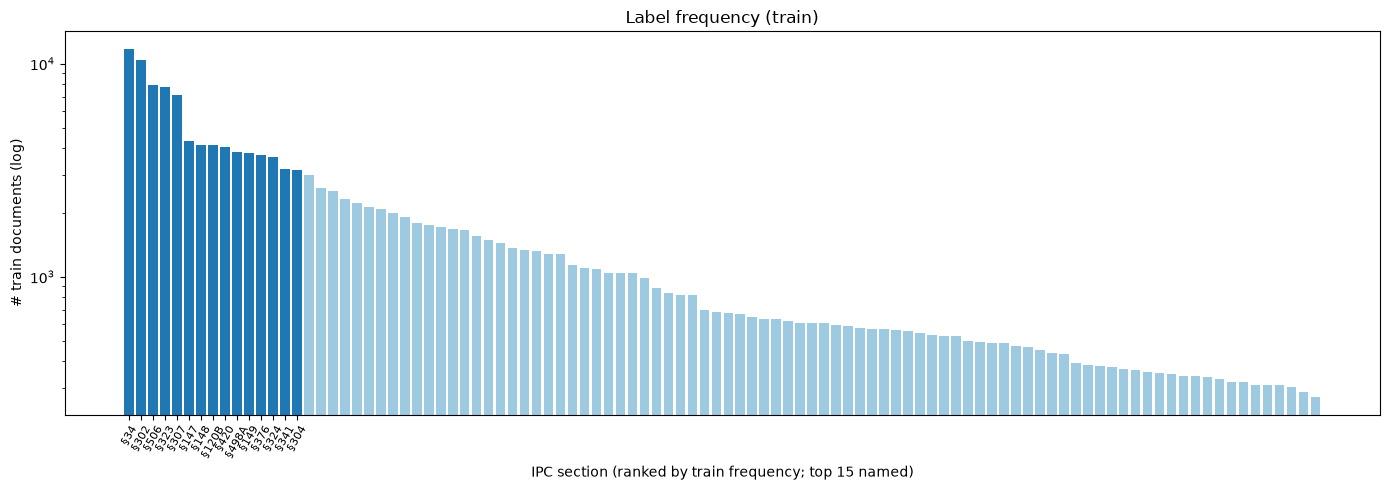

In [2]:
counts = eda.label_counts(dfs["train"], label_list)
eda.plot_label_frequency(counts, OUT / "label_frequency.png");
statutes = pd.read_parquet(PROC / "statutes.parquet").set_index("section_id")["text"]
top = counts.sort_values(ascending=False).head(15).to_frame()
top["statute text (first 90 chars)"] = [statutes[s][:90] for s in top.index]
top

In [3]:
print("max/min train count ratio:", counts.max() / counts.min())
print("least frequent 10:"); print(counts.sort_values().head(10).to_dict())

max/min train count ratio: 43.20220588235294
least frequent 10:
{'450': 272, '200': 287, '190': 305, '494': 310, '389': 310, '366A': 310, '338': 319, '415': 319, '228': 330, '155': 338}


## 2. Labels per document

,train,dev,test
count,42835.00,10200.00,13039.00
mean,3.70,3.91,3.90
std,2.58,2.54,2.51
min,1.00,1.00,1.00
25%,2.00,2.00,2.00
50%,3.00,3.00,3.00
75%,5.00,5.00,5.00
max,31.00,28.00,23.00


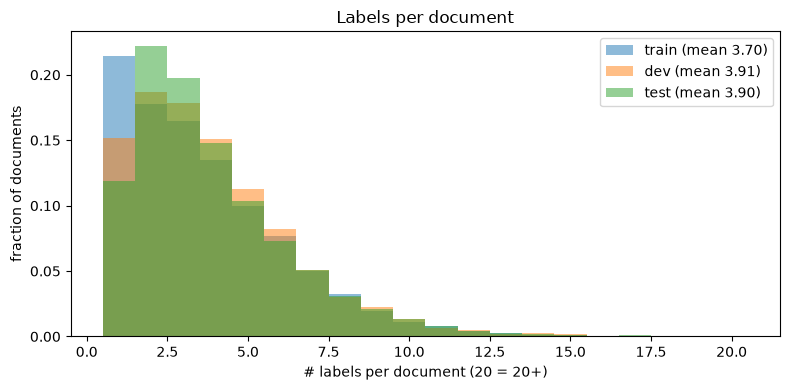

In [4]:
eda.plot_labels_per_doc(dfs, OUT / "labels_per_doc.png");
pd.DataFrame({s: d["labels"].map(len).describe() for s, d in dfs.items()}).round(2)

## 3. Document length (words)

The red line marks ~400 words, roughly what fits into BERT's 512-token window.

,train,dev,test
mean,1191.5,1329.2,1290.0
median,458.0,579.0,567.0
p90,2898.0,3110.0,2960.2
p95,4128.0,4486.0,4271.3
% > 400 words,54.1,59.5,59.4


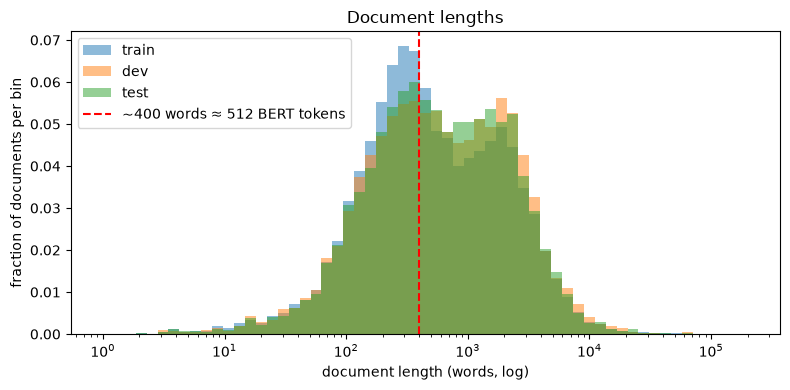

In [5]:
eda.plot_doc_lengths(dfs, OUT / "doc_lengths.png");
lens = {s: d["text"].str.split().str.len() for s, d in dfs.items()}
summary = pd.DataFrame({s: {"mean": l.mean(), "median": l.median(), "p90": l.quantile(.9), "p95": l.quantile(.95),
                            "% > 400 words": 100 * (l > eda.BERT_WORD_LIMIT).mean()} for s, l in lens.items()}).round(1)
summary

## 4. Top-20 label co-occurrence pairs (train)

,pair,count,P(b|a),P(a|b),jaccard
0,§302 & §34,3650,0.351,0.311,0.197
1,§147 & §148,3515,0.812,0.849,0.709
2,§323 & §506,3394,0.438,0.430,0.277
3,§323 & §34,3278,0.423,0.279,0.202
4,§148 & §149,2833,0.684,0.741,0.552
5,§307 & §34,2830,0.397,0.241,0.176
6,§147 & §149,2674,0.618,0.700,0.488
7,§302 & §307,2597,0.250,0.365,0.174
8,§34 & §506,2431,0.207,0.308,0.141
9,§302 & §304,2174,0.209,0.689,0.191


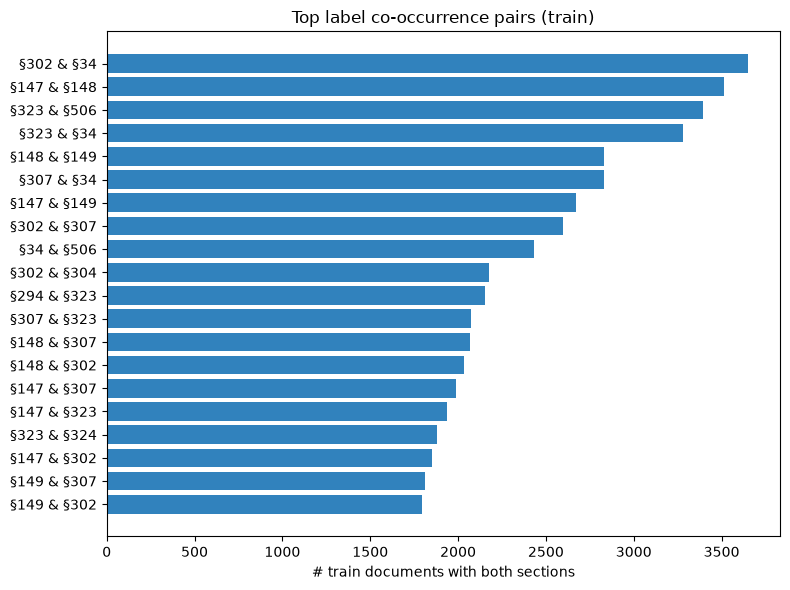

In [6]:
pairs = eda.cooccurrence_pairs(dfs["train"], top_k=20)
eda.plot_cooccurrence(pairs, OUT / "cooccurrence_top20.png")
pairs.to_csv(OUT / "cooccurrence_top20.csv", index=False)
pairs.drop(columns=["a", "b"])

## 5. Head / mid / tail buckets (train-frequency tertiles)

Saved to `data/processed/label_buckets.json` for later per-bucket evaluation.

head: 34 labels, train docs/label [1329, 11751], 75.3% of label occurrences
mid : 33 labels, train docs/label [544, 1322], 16.6% of label occurrences
tail: 33 labels, train docs/label [272, 533], 8.2% of label occurrences


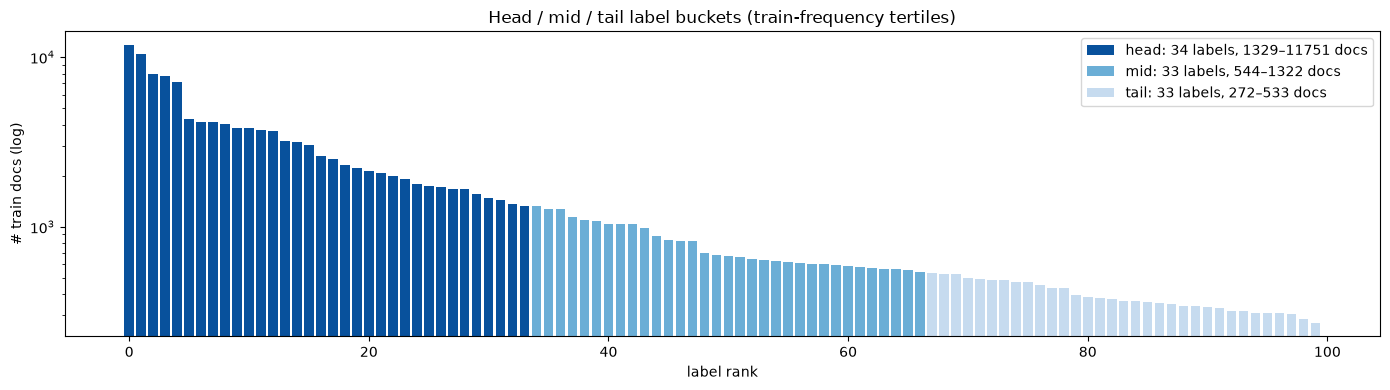

In [7]:
buckets = eda.tertile_buckets(counts)
with open(PROC / "label_buckets.json", "w") as f:
    json.dump(buckets, f, indent=1)
eda.plot_buckets(counts, buckets, OUT / "label_buckets.png")
for b in ["head", "mid", "tail"]:
    lab = buckets[b]
    share = counts[lab].sum() / counts.sum()
    print(f"{b:4s}: {len(lab)} labels, train docs/label {buckets['ranges'][b]}, {100*share:.1f}% of label occurrences")

## 6. Data-quality notes

* Statute numbers are often still written in the facts ("Section302 read with Section 34"). `src/inspect_data.py` finds ~37% of gold labels literally named as `section <N>` in the text, in all three splits. This is a property of the released dataset; it advantages lexical models and is discussed in the report.
* The label set contains general/procedural sections (2, 3, 4, 5) and a repealed section (13, "Rep. by the A.O. 1950").
* ~0.6% of documents are under 10 words (e.g. just a judge's name); they are kept to stay comparable with the benchmark but are unlearnable.

In [8]:
short = {k: int((v < 10).sum()) for k, v in lens.items()}
print("docs < 10 words:", short)
for s in ["2", "3", "4", "5", "13"]:
    print(f"§{s}: {counts[s]} train docs | {statutes[s][:100]}")

docs < 10 words: {'train': 238, 'dev': 54, 'test': 65}
§2: 343 train docs | Every person shall be liable to punishment under this Code and not otherwise for every act or omissi
§3: 1038 train docs | Any person liable, by any Indian law to be tried for an offence committed beyond India shall be deal
§4: 367 train docs | The provisions of this Code apply also to any offence committed by (1) any citizen of India in any p
§5: 454 train docs | Nothing in this Act shall affect the provisions of any Act for punishing mutiny and desertion of off
§13: 341 train docs | Rep. by the A.O. 1950.
